## Импорт библиотек и данных

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.core.pylabtools import figsize
from sklearn.model_selection import train_test_split


from ml3_03_data_split_methods import (
    split_random_train_test,
    split_random_train_validation_test,
    split_by_date_train_test,
    split_by_dates_train_validation_test,
    split_by_date_ratio_train_test,
    split_by_date_ratio_train_validation_test,
)




RANDOM_STATE = 21
DATA_PATH = (r".\data\train_df_processed_0.75.csv")

df = pd.read_csv(DATA_PATH)
df["created"] = pd.to_datetime(df["created"])

df['Elevator'].sum()

np.int64(18977)

## Разделить данные случайно на 2 части с параметром test_size (доля от 0 до 1), вернуть обучающую и тестовую выборки.

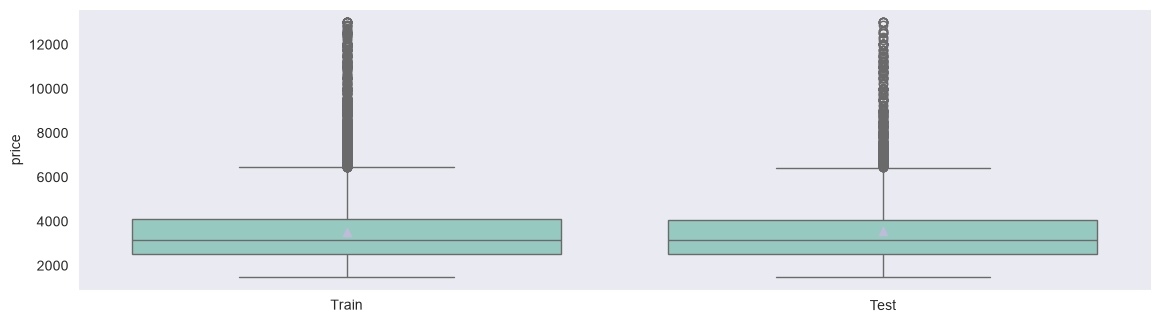

Размер df_train =  (27213, 24) 																		 Размер df_test = (9071, 24)


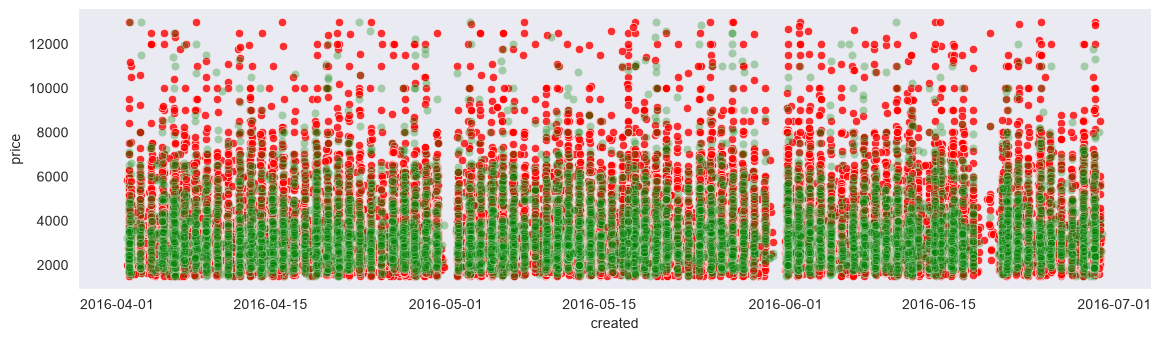

In [2]:
df_train, df_test = train_test_split(df, test_size=0.25, random_state=RANDOM_STATE, shuffle=True)

df_train_tmp = df_train[['price']].copy()
df_train_tmp['set'] = 'Train'

df_test_tmp = df_test[['price']].copy()
df_test_tmp['set'] = 'Test'

combined = pd.concat([df_train_tmp, df_test_tmp])

sns.set_style('dark')
sns.relplot(height=3.38, aspect=3.38)
sns.boxplot(x='set', y='price', data=combined, showmeans=True)
plt.xlabel('')
plt.show()

print('Размер df_train = ', df_train.shape, '\t' * 18, 'Размер df_test =', df_test.shape)
sns.set_style('dark')
sns.relplot(height=3.38, aspect=3.38)
sns.scatterplot(df_train, y='price', x='created', color='red', alpha=0.8)
sns.scatterplot(df_test, y='price', x='created', color='green', alpha=0.3);

## Случайно разделить данные на 3 части с параметрами validation_size и test_size, вернуть train, validation и test выборки.

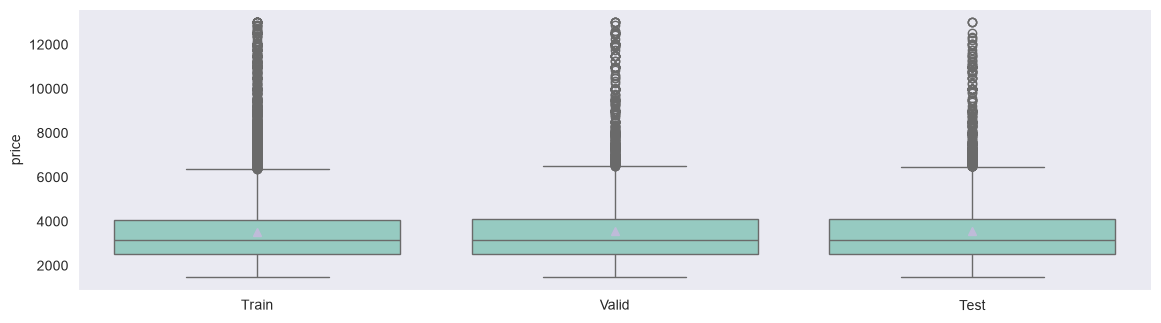

Размер df_train =  (24672, 24) 								 Размер df_valid = (6169, 24) 								 Размер df_test = (5443, 24)


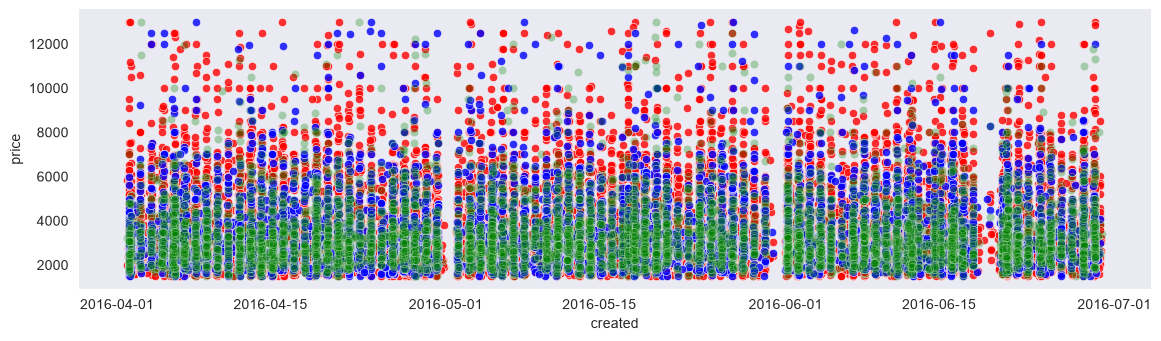

In [3]:
test_size = 0.15
validation_size = 0.2
df_train_valid, df_test = train_test_split(df, test_size=test_size, random_state=RANDOM_STATE, shuffle=True)
df_train, df_valid = train_test_split(df_train_valid, test_size=validation_size, random_state=RANDOM_STATE,
                                      shuffle=True)

df_train_tmp = df_train[['price']].copy()
df_train_tmp['set'] = 'Train'

df_valid_tmp = df_valid[['price']].copy()
df_valid_tmp['set'] = 'Valid'

df_test_tmp = df_test[['price']].copy()
df_test_tmp['set'] = 'Test'

combined = pd.concat([df_train_tmp, df_valid_tmp, df_test_tmp])

sns.set_style('dark')
sns.relplot(height=3.38, aspect=3.38)
sns.boxplot(x='set', y='price', data=combined, showmeans=True)
plt.xlabel('')
plt.show()
print('Размер df_train = ', df_train.shape, '\t' * 8, 'Размер df_valid =', df_valid.shape, '\t' * 8, 'Размер df_test =',
      df_test.shape)

sns.set_style('dark')
sns.relplot(height=3.38, aspect=3.38)
sns.scatterplot(df_train, y='price', x='created', color='red', alpha=0.8)
sns.scatterplot(df_valid, y='price', x='created', color='blue', alpha=0.8)
sns.scatterplot(df_test, y='price', x='created', color='green', alpha=0.3);

## Разделить данные на 2 части с параметром date_split, вернуть train и test выборки, разделенные по параметру date_split.

In [4]:
test_size = 0.2

df_sorted = df.copy()
df_sorted['created'] = pd.to_datetime(df_sorted['created'])
df_sorted = df_sorted.sort_values('created')

split_idx = int(len(df_sorted) * (1 - test_size))

df_train = df_sorted.iloc[:split_idx].copy()
df_test = df_sorted.iloc[split_idx:].copy()

date_split = df_test['created'].min()

print(df_train.shape)
print(df_test.shape)
print('date_split:', date_split)

(29027, 24)
(7257, 24)
date_split: 2016-06-12 08:18:50


In [5]:
def split_by_date(df, date_split, date_column='created'):
    """
    Делит df на две части по дате date_split.

    df_train — строки, где дата меньше date_split.
    df_test  — строки, где дата больше или равна date_split.
    """
    df = df.copy()
    df[date_column] = pd.to_datetime(df[date_column])
    date_split = pd.to_datetime(date_split)

    df_train = df[df[date_column] < date_split].copy()
    df_test = df[df[date_column] >= date_split].copy()

    return df_train, df_test


df_train, df_test = split_by_date(df, date_split=date_split, date_column='created')

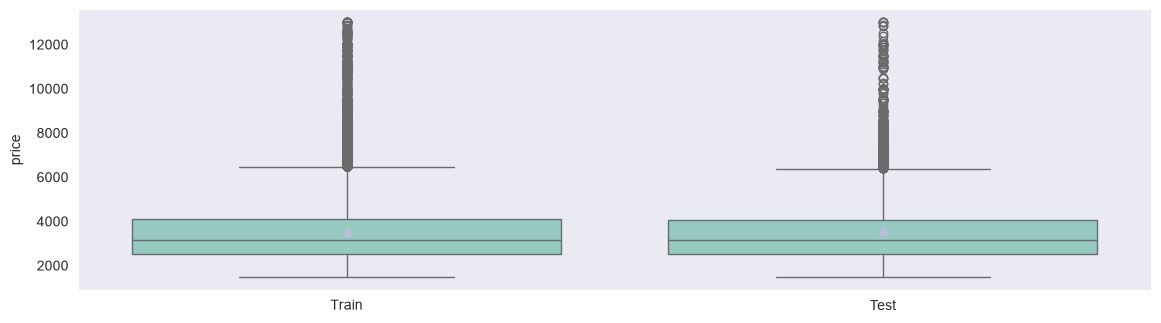

Размер df_train =  (29027, 24) 																		 Размер df_test = (7257, 24)


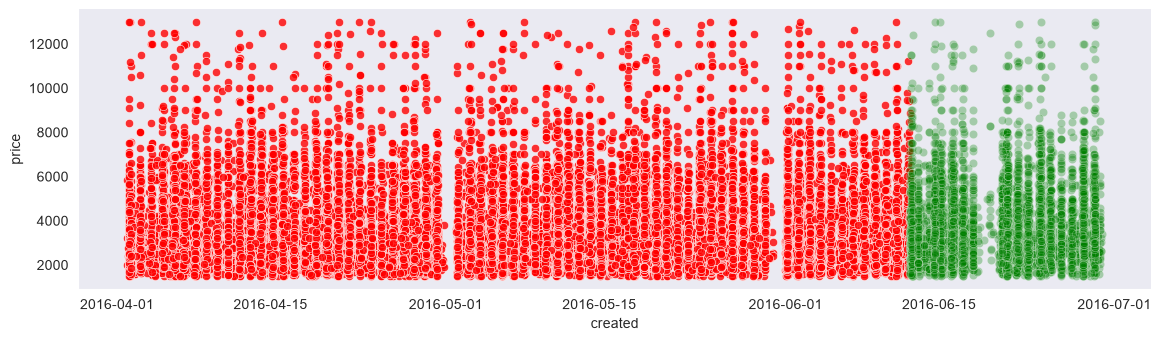

In [6]:
df_train_tmp = df_train[['price']].copy()
df_train_tmp['set'] = 'Train'

df_test_tmp = df_test[['price']].copy()
df_test_tmp['set'] = 'Test'

combined = pd.concat([df_train_tmp, df_test_tmp])

sns.set_style('dark')
sns.relplot(height=3.38, aspect=3.38)
sns.boxplot(x='set', y='price', data=combined, showmeans=True)
plt.xlabel('')
plt.show()

print('Размер df_train = ', df_train.shape, '\t' * 18, 'Размер df_test =', df_test.shape)
sns.set_style('dark')
sns.relplot(height=3.38, aspect=3.38)
sns.scatterplot(df_train, y='price', x='created', color='red', alpha=0.8)
sns.scatterplot(df_test, y='price', x='created', color='green', alpha=0.3);

## Разделить данные на 3 части с параметрами validation_date и test_date, вернуть train, validation и test выборки, разделенные по входным параметрам.

In [7]:
df_sorted = df.copy()
df_sorted['created'] = pd.to_datetime(df_sorted['created'])
df_sorted = df_sorted.sort_values('created')

valid_size = 0.2
test_size = 0.2

n = len(df_sorted)

train_end = int(n * (1 - valid_size - test_size))
valid_end = int(n * (1 - test_size))

df_train = df_sorted.iloc[:train_end].copy()
df_valid = df_sorted.iloc[train_end:valid_end].copy()
df_test = df_sorted.iloc[valid_end:].copy()

validation_date = df_valid['created'].min()
test_date = df_test['created'].min()

print(df_train.shape)
print(df_valid.shape)
print(df_test.shape)

print('validation_date:', validation_date)
print('test_date:', test_date)


(21770, 24)
(7257, 24)
(7257, 24)
validation_date: 2016-05-24 18:08:52
test_date: 2016-06-12 08:18:50


In [8]:
def split_by_dates(df, validation_date, test_date, date_column='created'):

    df = df.copy()
    df[date_column] = pd.to_datetime(df[date_column])

    validation_date = pd.to_datetime(validation_date)
    test_date = pd.to_datetime(test_date)

    if validation_date >= test_date:
        raise ValueError('validation_date должна быть меньше test_date')

    df_train = df[df[date_column] < validation_date].copy()

    df_validation = df[
        (df[date_column] >= validation_date) &
        (df[date_column] < test_date)
    ].copy()

    df_test = df[df[date_column] >= test_date].copy()

    return df_train, df_valid, df_test

df_train, df_validation, df_test = split_by_dates(
    df,
    validation_date=validation_date,
    test_date=test_date,
    date_column='created'
)

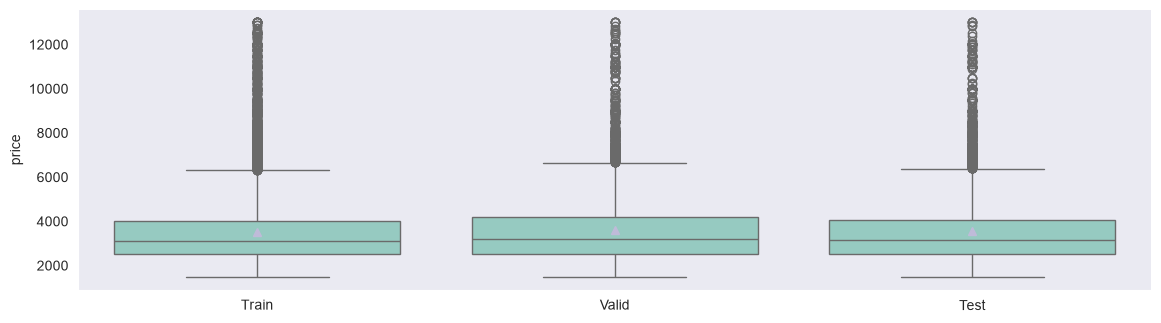

Размер df_train =  (21770, 24) 								 Размер df_valid = (7257, 24) 								 Размер df_test = (7257, 24)


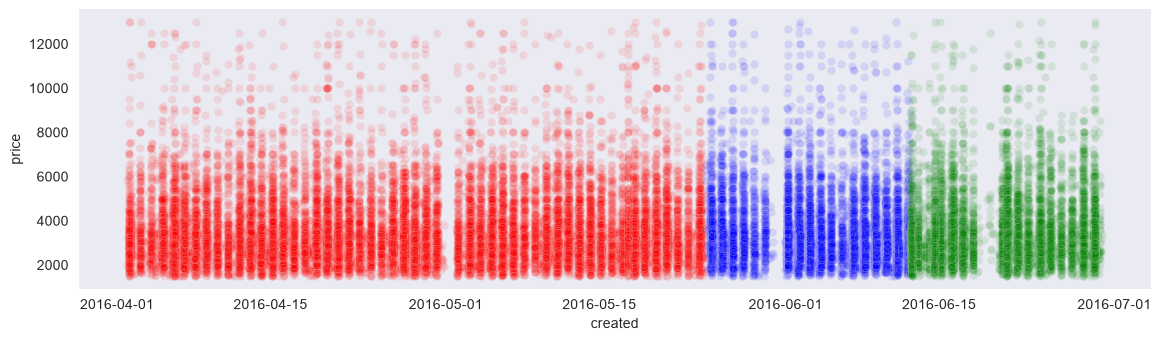

In [9]:
df_train_tmp = df_train[['price']].copy()
df_train_tmp['set'] = 'Train'

df_valid_tmp = df_valid[['price']].copy()
df_valid_tmp['set'] = 'Valid'

df_test_tmp = df_test[['price']].copy()
df_test_tmp['set'] = 'Test'

combined = pd.concat([df_train_tmp, df_valid_tmp, df_test_tmp])

sns.set_style('dark')
sns.relplot(height=3.38, aspect=3.38)
sns.boxplot(x='set', y='price', data=combined, showmeans=True)
plt.xlabel('')
plt.show()
print('Размер df_train = ', df_train.shape, '\t' * 8, 'Размер df_valid =', df_valid.shape, '\t' * 8, 'Размер df_test =',
      df_test.shape)

sns.set_style('dark')
sns.relplot(height=3.38, aspect=3.38)
sns.scatterplot(df_train, y='price', x='created', color='red', alpha=0.1)
sns.scatterplot(df_valid, y='price', x='created', color='blue', alpha=0.1)
sns.scatterplot(df_test, y='price', x='created', color='green', alpha=0.1);

In [10]:
from datetime import datetime
print("=" * 38, datetime.now(), 'jacquieb', sep="\n")

2026-10-11 07:10:02.320657
jacquieb


In [11]:
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# from IPython.core.pylabtools import figsize
# from sklearn.model_selection import train_test_split
#
#
# from ml3_03_data_split_methods import (
#     split_random_train_test,
#     split_random_train_validation_test,
#     split_by_date_train_test,
#     split_by_dates_train_validation_test,
#     split_by_date_ratio_train_test,
#     split_by_date_ratio_train_validation_test,
# )
#
#
#
#
# RANDOM_STATE = 21
# DATA_PATH = (r".\data\train_df_processed_0.75.csv")
#
# df = pd.read_csv(DATA_PATH)
# df["created"] = pd.to_datetime(df["created"])
#
# df['Elevator'].sum()
#
#
# df_train, df_test = split_random_train_test(
#     df,
#     test_size=0.2
# )
#
# df_train_tmp = df_train[['price']].copy()
# df_train_tmp['set'] = 'Train'
#
# df_test_tmp = df_test[['price']].copy()
# df_test_tmp['set'] = 'Test'
#
# combined = pd.concat([df_train_tmp, df_test_tmp])
#
# sns.set_style('dark')
# sns.relplot(height=3.38, aspect=3.38)
# sns.boxplot(x='set', y='price', data=combined, showmeans=True)
# plt.xlabel('')
# plt.show()
#
# print('Размер df_train = ', df_train.shape, '\t' * 18, 'Размер df_test =', df_test.shape)
# sns.set_style('dark')
# sns.relplot(height=3.38, aspect=3.38)
# sns.scatterplot(df_train, y='price', x='created', color='red', alpha=0.8)
# sns.scatterplot(df_test, y='price', x='created', color='green', alpha=0.3);